# 04 — Anomaly detection and development evaluation

**Question:** Do the temporal features from Notebook 03 help distinguish annotated departures on other recordings, and what alert burden do they create?

We compare **eight level departures (Set A)** with **all 19 features (Set B)** using two simple detectors. Each detector calculates a score; a separate set of recordings supplies a cutoff; a short persistence rule converts scores into alerts. These are different operations and are evaluated separately.

This is a **development experiment with training annotations**, not an automatic diagnosis system. Annotations identify initial candidate-normal examples in fitting and cutoff-calibration recordings. They are never model inputs. A new recording supplies only its first fixed 60 seconds for its local sensor medians, without consulting labels. Its later annotations are used retrospectively to assess the frozen decisions.

The eight reserved experiments remain unopened. All recordings come from one testbed. Results describe transfer between its experiments, not future deployment or generalisation between companies.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest

from ts_anomaly.skab import METRICS, load_development
from ts_anomaly.features import engineer_recording
from ts_anomaly.detection import fit_rarity, rarity_scores, calibrate_threshold, causal_alerts
from ts_anomaly.evaluation import label_windows, point_metrics, episode_metrics, observed_episodes

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
settings = json.loads((ROOT / 'configs/skab.json').read_text())
feature_settings = settings['features']
baseline_settings = settings['baselines']
experiment = settings['detection']
OUT = ROOT / 'outputs/skab_detection'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 14)
recordings, annotations = load_development(ROOT / 'data/skab', settings)
manifest = pd.DataFrame(settings['files'])
development_ids = manifest.loc[manifest.partition.eq('development'), 'recording_id'].tolist()
reserved_ids = set(manifest.loc[manifest.partition.eq('reserved_test'), 'recording_id'])
assert set(development_ids) == set(annotations)
assert reserved_ids.isdisjoint(recordings)
print(f'{len(development_ids)} development recordings; {len(reserved_ids)} reserved recordings not opened.')
print('Source commit:', settings['source_commit'])
print('Python:', sys.version.split()[0], '| scikit-learn:', version('scikit-learn'))

26 development recordings; 8 reserved recordings not opened.
Source commit: b2c0d46c2971dcbfe71e26087b6d231998bb91c2
Python: 3.13.2 | scikit-learn: 1.9.1


## 1. Information boundaries: three roles, three different jobs

| Operation | Permitted information | What is calculated? |
|---|---|---|
| Local sensor calibration | First 60 elapsed seconds of each recording, without annotations | The eight reference medians used by Notebook 03; 180 seconds is a separate sensitivity experiment |
| Detector fitting | Complete post-180-second feature vectors before the first positive anomaly **or changepoint** annotation, in fitting recordings only | Marginal feature distributions or isolation trees |
| Cutoff calibration | The same initial candidate-normal definition, in different recordings | The 95th and 99th percentiles of their frozen detector scores |
| Development assessment | Other whole recordings, after 180 seconds | Frozen scores and alerts; labels consulted for assessment only |

We assign recordings in numeric filename order, round-robin within each intervention family, to three groups. Each group is assessed once; the other two groups have separate fitting and cutoff-calibration roles. The assignment uses file identities, not observed detection performance. Families balance the groups and are not predictors.

This is **annotation-assisted normal-reference training**. It does not assume that every label-zero recovery interval is healthy. The pre-annotation portion is only *candidate normal*. In an operational application, its equivalent would require credible commissioning or maintenance evidence.

The separate normal file is not used here: Notebook 02 found source overlap with `other/5`, and its operating levels differ from many experiments. `other/5` can remain in a development group because that overlapping separate file contributes no fitting or cutoff-calibration rows.

In [2]:
assert experiment['folds'] == 3  # Three distinct roles define this experiment.
fold_rows = []
for family in ['other', 'valve1', 'valve2']:
    identifiers = [name for name in development_ids if name.startswith(family + '/')]
    identifiers.sort(key=lambda name: int(name.split('/')[1]))
    for position, name in enumerate(identifiers):
        fold_rows.append({'recording_id': name, 'family': family,
                          'fold': position % experiment['folds']})
folds = pd.DataFrame(fold_rows).set_index('recording_id')
assert set(folds.index) == set(development_ids)
roles = []
for fold in range(3):
    fit_ids = folds.index[folds.fold.eq((fold + 1) % 3)].tolist()
    cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
    assess_ids = folds.index[folds.fold.eq(fold)].tolist()
    assert set(fit_ids).isdisjoint(cutoff_ids + assess_ids)
    assert set(cutoff_ids).isdisjoint(assess_ids)
    roles.append({'assessment_fold': fold, 'fit_recordings': ', '.join(fit_ids),
                  'cutoff_recordings': ', '.join(cutoff_ids),
                  'assessment_recordings': ', '.join(assess_ids)})
role_table = pd.DataFrame(roles)
display(pd.crosstab(folds.family, folds.fold))
display(folds.sort_values(['fold', 'family']).reset_index())
display(pd.DataFrame({'assessment_fold': [0, 1, 2], 'fit_fold': [1, 2, 0], 'cutoff_fold': [2, 0, 1]}))
folds.to_csv(OUT / 'recording_folds.csv')
role_table.to_csv(OUT / 'information_roles.csv', index=False)

fold,0,1,2
family,,,
other,4,4,3
valve1,4,4,4
valve2,1,1,1


,recording_id,family,fold
0,other/1,other,0
1,other/5,other,0
2,other/9,other,0
3,other/13,other,0
4,valve1/0,valve1,0
5,valve1/4,valve1,0
6,valve1/8,valve1,0
7,valve1/12,valve1,0
8,valve2/0,valve2,0
9,other/2,other,1


,assessment_fold,fit_fold,cutoff_fold
0,0,1,2
1,1,2,0
2,2,0,1


## 2. Reuse the frozen feature definitions and expose unavailable cases

Features are rebuilt with the unchanged Notebook 03 functions. No detector sees a recording identifier, family, elapsed intervention schedule, anomaly label or changepoint label. The local calibration period is fixed before labels are consulted.

All primary comparisons start on five-second targets wholly after elapsed 180 seconds. Set A and Set B use the **same complete 19-feature rows for fitting and cutoff calibration**. In assessment we preserve each set's own availability, and also evaluate both on the common Set B availability. For the common comparison, missing timestamps reset **both alert histories**, not only the metric denominator.

An unavailable score is not a zero score or a declaration of normality. Calibration failure and collection gaps remain visible. The 180-second sensitivity comparison uses the same endpoints and reports its own additional support losses.

In [3]:
features, calibration_rows, support_rows = {}, [], []
step = pd.Timedelta(baseline_settings['aggregation_interval'])
for duration in baseline_settings['calibration_seconds']:
    for name in development_ids:
        values, support, references = engineer_recording(
            recordings[name], list(METRICS), feature_settings['slope_measurements'],
            feature_settings['variability_measurements'], feature_settings['history_measurements'],
            calibration_seconds=duration, frequency=baseline_settings['aggregation_interval'],
            min_count=baseline_settings['minimum_bin_observations'], window=feature_settings['window'],
            minimum_occupancy=baseline_settings['minimum_occupancy'],
            max_gap=settings['gap_threshold'], nominal_interval=settings['nominal_interval'])
        boundary = recordings[name].timestamp.iloc[0] + pd.Timedelta(
            seconds=experiment['assessment_start_seconds'])
        features[duration, name] = values.loc[values.index - step >= boundary]
        calibration_rows.append(references.assign(recording_id=name))
        selected_support = support.loc[support.timestamp.isin(features[duration, name].index)]
        reasons = selected_support.groupby(['feature', 'reason']).size().rename('endpoints').reset_index()
        support_rows.append(reasons.assign(recording_id=name, calibration_seconds=duration))
calibration = pd.concat(calibration_rows, ignore_index=True)
support_reasons = pd.concat(support_rows, ignore_index=True)
feature_sets = {'A_level': [f'{name}__level' for name in METRICS],
                'B_expanded': list(features[60, development_ids[0]].columns)}
assert len(feature_sets['A_level']) == 8 and len(feature_sets['B_expanded']) == 19
calibration.to_csv(OUT / 'local_calibration.csv', index=False)
support_reasons.to_csv(OUT / 'feature_support_reasons.csv', index=False)

In [4]:
reference_masks, window_labels, native_labels = {}, {}, {}
availability_rows = []
for name in development_ids:
    labels = annotations[name].set_index('timestamp')
    native_labels[name] = labels.anomaly
    marked = labels.anomaly.eq(1) | labels.changepoint.eq(1)
    first_mark = labels.index[marked][0] if marked.any() else labels.index[-1] + pd.Timedelta('1s')
    window_labels[name] = label_windows(labels.anomaly, features[60, name].index,
                                       frequency=step, min_count=baseline_settings['minimum_bin_observations'])
    for duration in baseline_settings['calibration_seconds']:
        values = features[duration, name]
        complete = values.notna().all(axis=1)
        reference_masks[duration, name] = complete & (values.index <= first_mark)
        for set_name, columns in feature_sets.items():
            available = values[columns].notna().all(axis=1)
            availability_rows.append({'recording_id': name, 'calibration_seconds': duration,
                                      'feature_set': set_name, 'requested': len(values),
                                      'available': int(available.sum()),
                                      'availability': available.mean(),
                                      'candidate_normal_rows': int(reference_masks[duration, name].sum()),
                                      'first_annotation': first_mark})
availability = pd.DataFrame(availability_rows)
display(availability.groupby(['calibration_seconds', 'feature_set'])[
    ['requested', 'available']].sum())
display(availability.loc[availability.candidate_normal_rows.eq(0),
                         ['recording_id', 'calibration_seconds', 'feature_set', 'available']])
print('Pure / mixed / unsupported evaluation bins:')
display(pd.concat(window_labels).status.value_counts().rename('endpoints').to_frame())
availability.to_csv(OUT / 'availability_by_recording.csv', index=False)

requested  available
calibration_seconds feature_set                      
60                  A_level           5150       4885
                    B_expanded        5150       4864
180                 A_level           5150       4743
                    B_expanded        5150       4727

,recording_id,calibration_seconds,feature_set,available
12,other/13,60,A_level,0
13,other/13,60,B_expanded,0
14,other/13,180,A_level,0
15,other/13,180,B_expanded,0
20,other/2,60,A_level,142
21,other/2,60,B_expanded,137
22,other/2,180,A_level,0
23,other/2,180,B_expanded,0


Pure / mixed / unsupported evaluation bins:


,endpoints
status,
pure,5010
insufficient_labels,100
mixed,40


**Reading the support audit.** Zero candidate-normal rows means that a recording contributes nothing when it has a fitting or cutoff-calibration role. It is still assessed when held out. With 60-second local calibration, `other/13` has no complete level reference and `other/2` has no eligible post-180-second pre-annotation training rows because of its gap. The latter can still supply later assessment scores. Complete numerical outputs retain both cases.

Five-second label bins are retrospective summaries: a bin needs at least four labels and must contain only zeros or only ones. Mixed transition bins remain unknown for point metrics. They do **not** reset operational alerts; only unavailable features do that.

## 3. Fit two small detectors; calibrate their cutoffs on different recordings

**Empirical rarity.** For each feature, store its sorted candidate-normal values. For a new value, count reference values at or below it and at or above it, including ties, with one-count finite-sample smoothing. The score is one minus twice the smaller tail fraction, clipped at zero. The vector score is the largest feature score. It answers: *is any feature unusual relative to these reference examples?*

This method handles tied and zero-spread features without division or arbitrary epsilon constants. Its deliberate limitation is **saturation**: values outside a fitted range have identical maximum rarity, however far outside they lie. Adding features also increases opportunities for a large maximum. Separate cutoff calibration is therefore essential; a cutoff at the score ceiling may produce no strict exceedances. These scores are not anomaly probabilities or calibrated p-values.

**Isolation Forest.** Random trees isolate feature vectors; short average isolation paths produce higher anomaly scores. We use 200 trees, at most 256 fitting examples per tree, and a fixed seed. Scores are `-score_samples`; scikit-learn's default binary cutoff is not used. The method can represent combinations, but its output alone does not explain a physical fault. Neither method needs standardisation for this comparison. There is no automatic feature selection or hyperparameter search.

The primary cutoff is the 99th percentile of separate candidate-normal calibration scores; the 95th percentile is a declared sensitivity check. **Neither percentile guarantees a 1% or 5% future false-alert rate**, especially with dependence, ties and transfer between recordings. [Isolation Forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html), [novelty detection assumptions](https://scikit-learn.org/stable/modules/outlier_detection.html).

In [5]:
training_values, scoring, component_tables = {}, {}, []
model_rows, threshold_rows = [], []
for duration in baseline_settings['calibration_seconds']:
    for fold in range(3):
        fit_ids = folds.index[folds.fold.eq((fold + 1) % 3)].tolist()
        cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
        assess_ids = folds.index[folds.fold.eq(fold)].tolist()
        fit_all = pd.concat([features[duration, name].loc[reference_masks[duration, name]]
                             for name in fit_ids], keys=fit_ids, names=['recording_id'])
        cutoff_all = pd.concat([features[duration, name].loc[reference_masks[duration, name]]
                                for name in cutoff_ids], keys=cutoff_ids, names=['recording_id'])
        assert len(fit_all) and len(cutoff_all)
        for set_name, columns in feature_sets.items():
            fit_values, cutoff_values = fit_all[columns], cutoff_all[columns]
            rarity = fit_rarity(fit_values)
            forest = IsolationForest(n_estimators=experiment['isolation_trees'],
                                     max_samples=experiment['isolation_max_samples'],
                                     random_state=experiment['primary_seed'], n_jobs=1)
            forest.fit(fit_values)
            rarity_cutoff, _ = rarity_scores(rarity, cutoff_values)
            forest_cutoff = pd.Series(-forest.score_samples(cutoff_values), index=cutoff_values.index)
            training_values[duration, fold, set_name] = fit_values
            for method, calibration_scores in [('rarity', rarity_cutoff),
                                                       ('isolation', forest_cutoff)]:
                model_rows.append({'calibration_seconds': duration, 'fold': fold,
                                   'feature_set': set_name, 'method': method, 'fit_rows': len(fit_values),
                                   'fit_recordings_contributing': fit_values.index.get_level_values(0).nunique(),
                                   'cutoff_rows': len(cutoff_values),
                                   'cutoff_recordings_contributing': cutoff_values.index.get_level_values(0).nunique(),
                                   'constant_fit_features': ', '.join(fit_values.columns[fit_values.nunique().le(1)])})
                for quantile in experiment['threshold_quantiles']:
                    threshold_rows.append({'calibration_seconds': duration, 'fold': fold,
                                           'feature_set': set_name, 'method': method,
                                           **calibrate_threshold(calibration_scores, quantile).to_dict()})
            for name in assess_ids:
                values = features[duration, name][columns]
                rarity_score, components = rarity_scores(rarity, values)
                forest_score = pd.Series(np.nan, index=values.index, name='score')
                finite = values.notna().all(axis=1)
                if finite.any():
                    forest_score.loc[finite] = -forest.score_samples(values.loc[finite])
                scoring[duration, name, set_name, 'rarity'] = rarity_score
                scoring[duration, name, set_name, 'isolation'] = forest_score
                component_tables.append(components.assign(recording_id=name, calibration_seconds=duration,
                                                           feature_set=set_name))
model_audit = pd.DataFrame(model_rows)
thresholds = pd.DataFrame(threshold_rows)
display(model_audit.loc[model_audit.calibration_seconds.eq(60)].round(4))
display(thresholds.loc[thresholds.calibration_seconds.eq(60) & thresholds['quantile'].eq(.99),
                      ['fold', 'feature_set', 'method', 'threshold', 'rows', 'distinct_scores',
                       'exceeded_fraction', 'threshold_at_maximum']].round(5))
model_audit.to_csv(OUT / 'model_fitting_audit.csv', index=False)
thresholds.to_csv(OUT / 'threshold_calibration.csv', index=False)

,calibration_seconds,fold,feature_set,method,fit_rows,fit_recordings_contributing,cutoff_rows,cutoff_recordings_contributing,constant_fit_features
0,60,0,A_level,rarity,665,8,663,8,
1,60,0,A_level,isolation,665,8,663,8,
2,60,0,B_expanded,rarity,665,8,663,8,
3,60,0,B_expanded,isolation,665,8,663,8,
4,60,1,A_level,rarity,663,8,663,8,
5,60,1,A_level,isolation,663,8,663,8,
6,60,1,B_expanded,rarity,663,8,663,8,
7,60,1,B_expanded,isolation,663,8,663,8,
8,60,2,A_level,rarity,663,8,665,8,
9,60,2,A_level,isolation,663,8,665,8,


,fold,feature_set,method,threshold,rows,distinct_scores,exceeded_fraction,threshold_at_maximum
1,0,A_level,rarity,0.99700,663,86,0.00000,True
3,0,A_level,isolation,0.58564,663,663,0.01056,False
5,0,B_expanded,rarity,0.99700,663,57,0.00000,True
7,0,B_expanded,isolation,0.55016,663,663,0.01056,False
9,1,A_level,rarity,0.99699,663,141,0.00000,True
11,1,A_level,isolation,0.59832,663,663,0.01056,False
13,1,B_expanded,rarity,0.99699,663,77,0.00000,True
15,1,B_expanded,isolation,0.56378,663,663,0.01056,False
17,2,A_level,rarity,0.99699,665,119,0.00000,True
19,2,A_level,isolation,0.55625,665,665,0.01053,False


**Observed cutoff behaviour.** Each primary fit/cutoff population contains about 663–665 complete vectors from eight contributing recordings. The rarity cutoff equals the maximum possible fitted score in every fold and feature set. We retain that result: this reference cannot distinguish increasingly severe out-of-range values. Isolation Forest has distinct calibration scores, but an approximately 1% exceedance in calibration does not guarantee transfer to the held-out recordings. These are dependent windows from eight runs, not hundreds of independent normal experiments; the extreme calibration percentile is supported by very few tail observations.

## 4. Convert scores into decisions without backdating

We compare an immediate rule with a rule requiring **three consecutive available five-second scores above the cutoff**. The latter issues its first alert at the third endpoint. Below-cutoff scores, unavailable features and gaps reset the run. There is no cooldown, event merging or retrospective filling of an annotated episode.

Evaluation has several complementary views:

- **Ranking:** average precision (AP), computed separately per recording on pure-label common bins. A constant-score comparator has AP equal to that recording's positive-label fraction. AP needs both classes; it is undefined for unavailable recordings, which remain in coverage counts.
- **Point decisions:** precision and recall without point adjustment, on the stated eligible observations. We also report positive-bin recall counting unavailable decisions as undetected.
- **Observed episodes:** only fully observed positive runs have complete onset/end evidence. Detection requires a *new alert start* within the episode; a standing alarm cannot claim a later episode. Delay is from the first positive native label to that actual alert endpoint. Gap-censored pieces are listed separately, not invented as complete incidents.
- **Burden:** new alerts at label-zero times per observed, monitored label-zero hour, plus the fraction of such time spent in alert. A label-negative alert is not proven false: annotations may be incomplete.

Exposure uses actual timestamps. No time is credited across a collection gap; decisions hold for at most five seconds. Mixed label boundaries and uncertain alert-time labels are reported explicitly. We do not extrapolate these short experiments into a production daily alert rate.

[Average precision definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html); [Kim et al., AAAI 2022: risks of point-adjusted evaluation](https://arxiv.org/abs/2109.05257).

In [6]:
cutoffs = thresholds.set_index(['calibration_seconds', 'fold', 'feature_set', 'method', 'quantile']).threshold
metric_rows, event_tables, decision_tables = [], [], []
for (duration, name, set_name, method), scores in scoring.items():
    fold = int(folds.loc[name, 'fold'])
    common = features[duration, name].notna().all(axis=1)
    labels = window_labels[name].label
    for population in ['common', 'own']:
        # Common support changes the decision stream itself, not only metric selection.
        stream = scores.where(common) if population == 'common' else scores
        for quantile in experiment['threshold_quantiles']:
            threshold = cutoffs.loc[duration, fold, set_name, method, quantile]
            for consecutive in experiment['consecutive_windows']:
                decisions = causal_alerts(stream, threshold, consecutive, frequency=step)
                point = point_metrics(labels, stream, decisions.alarm)
                episode, events = episode_metrics(native_labels[name], decisions, frequency=step,
                                                   max_gap=settings['gap_threshold'])
                identity = {'recording_id': name, 'family': folds.loc[name, 'family'], 'fold': fold,
                            'calibration_seconds': duration, 'feature_set': set_name, 'method': method,
                            'population': population, 'quantile': quantile, 'consecutive': consecutive}
                metric_rows.append({**identity, **point.to_dict(), **episode.to_dict()})
                event_tables.append(events.assign(**identity))
                decision_tables.append(decisions.assign(score=stream, label=labels, threshold=threshold,
                                                         **identity))
metrics = pd.DataFrame(metric_rows)
events = pd.concat(event_tables, ignore_index=True)
decisions = pd.concat(decision_tables).reset_index()
metrics.to_csv(OUT / 'metrics_by_recording.csv', index=False)
events.to_csv(OUT / 'observed_episode_results.csv', index=False)
decisions.to_csv(OUT / 'scores_and_decisions.csv.gz', index=False)
pd.concat(component_tables).reset_index().to_csv(OUT / 'rarity_components.csv.gz', index=False)
print('Every development recording is assessed once per experimental specification.')
assert metrics.groupby(['calibration_seconds', 'feature_set', 'method', 'population',
                        'quantile', 'consecutive']).recording_id.nunique().eq(26).all()

Every development recording is assessed once per experimental specification.


## 5. Compare feature sets on identical available observations

Each recording contributes one AP value, rather than allowing a long recording to dominate a pooled metric. Missing AP is excluded from the mean **and counted**. Counts, monitoring availability and whole-recording outcomes are reported alongside it. There is no IID confidence interval over temporally dependent rows, and raw scores from independently fitted folds are not pooled into one global ranking.

The paired plot compares Set A and Set B on the same common bins. A point above the diagonal favours the expanded features for ranking in that recording. This does not establish a useful cutoff or acceptable alert burden.

recordings  available_recordings  mean_AP  median_AP  \
method    feature_set                                                         
isolation A_level              26                    25    0.811      0.881   
          B_expanded           26                    25    0.771      0.846   
rarity    A_level              26                    25    0.701      0.782   
          B_expanded           26                    25    0.683      0.651   

                       minimum_AP  maximum_AP  mean_constant_score_AP  
method    feature_set                                                  
isolation A_level           0.235       0.993                   0.412  
          B_expanded        0.282       0.964                   0.412  
rarity    A_level           0.232       1.000                   0.412  
          B_expanded        0.284       0.972                   0.412

count   mean
family method    feature_set              
other  isolation A_level         10  0.868
                 B_expanded      10  0.807
       rarity    A_level         10  0.610
                 B_expanded      10  0.572
valve1 isolation A_level         12  0.744
                 B_expanded      12  0.712
       rarity    A_level         12  0.746
                 B_expanded      12  0.739
valve2 isolation A_level          3  0.886
                 B_expanded       3  0.884
       rarity    A_level          3  0.826
                 B_expanded       3  0.829

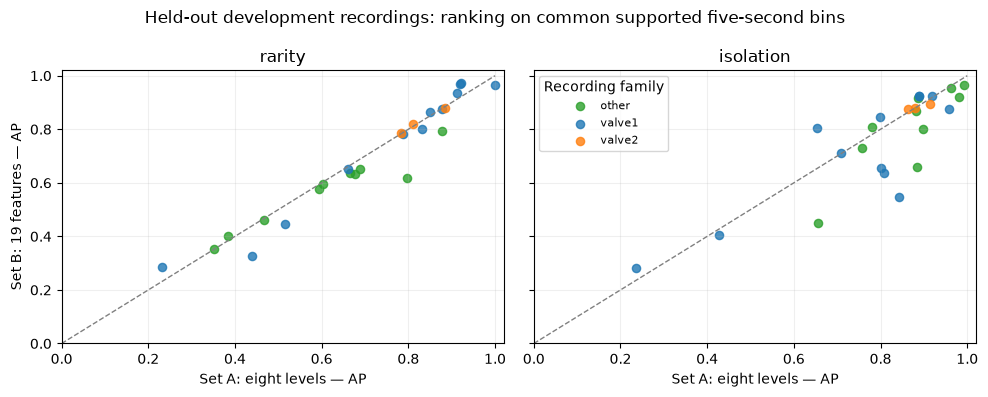

In [7]:
primary = metrics.loc[metrics.calibration_seconds.eq(60) & metrics.population.eq('common')
                      & metrics['quantile'].eq(experiment['primary_quantile'])].copy()
ranking = primary.loc[primary.consecutive.eq(1)].copy()
ranking['constant_score_AP'] = ranking.positive_common / ranking.common.replace(0, np.nan)
ranking_summary = ranking.groupby(['method', 'feature_set']).agg(
    recordings=('recording_id', 'size'), available_recordings=('average_precision', 'count'),
    mean_AP=('average_precision', 'mean'), median_AP=('average_precision', 'median'),
    minimum_AP=('average_precision', 'min'), maximum_AP=('average_precision', 'max'),
    mean_constant_score_AP=('constant_score_AP', 'mean'))
display(ranking_summary.round(3))
display(ranking.groupby(['family', 'method', 'feature_set']).average_precision.agg(['count', 'mean']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, method in zip(axes, ['rarity', 'isolation']):
    paired = ranking.loc[ranking.method.eq(method)].pivot(index='recording_id', columns='feature_set',
                                                          values='average_precision')
    for family, colour in [('other', 'tab:green'), ('valve1', 'tab:blue'), ('valve2', 'tab:orange')]:
        selected = paired.loc[paired.index.str.startswith(family + '/')]
        ax.scatter(selected.A_level, selected.B_expanded, label=family, color=colour, s=35, alpha=.8)
    ax.plot([0, 1], [0, 1], '--', color='grey', linewidth=1)
    ax.set(title=method, xlabel='Set A: eight levels — AP', xlim=(0, 1.02), ylim=(0, 1.02))
axes[0].set_ylabel('Set B: 19 features — AP')
axes[1].legend(title='Recording family', fontsize=8)
fig.suptitle('Held-out development recordings: ranking on common supported five-second bins')
fig.tight_layout(); fig.savefig(OUT / 'paired_ranking.png', dpi=140); plt.show()
ranking_summary.to_csv(OUT / 'ranking_summary.csv')

**Observed:** all methods have a ranking result for 25/26 recordings; `other/13` remains unavailable. Mean AP falls from **0.811 to 0.771** when Isolation Forest receives all 19 features, and from **0.701 to 0.683** for rarity. The paired points show exceptions, so this is not evidence that every temporal feature is useless. It is evidence against assuming that the expanded vector helps these two methods as a whole. Per-family and complete per-recording outputs preserve that heterogeneity.

## 6. Alert usefulness requires burden, delay and coverage together

The next table sums complete-episode counts and observed exposure; its rates are ratios of those totals. It also reports equal-recording AP separately above. Delay summaries use detected episodes only, so they must be read beside the number missed. A model that never alerts can have zero label-negative burden while detecting nothing.

The common-support policies use the same timestamps for both feature sets. The additional availability table shows how much more often Set A could produce an output. The separate `own` results are exported for that operational comparison; they must not be confused with the paired feature experiment.

,method,feature_set,consecutive,availability,detected_episodes,complete_episodes,episode_recall,median_detected_delay_s,negative_alerts_per_hour,negative_time_in_alert,all_positive_bin_recall
2,isolation,A_level,1,0.944,13.0,20.0,0.65,47.0,13.002,0.043,0.219
3,isolation,A_level,3,0.944,7.0,20.0,0.35,36.0,2.549,0.019,0.167
6,isolation,B_expanded,1,0.944,7.0,20.0,0.35,12.0,8.413,0.033,0.165
7,isolation,B_expanded,3,0.944,7.0,20.0,0.35,22.0,2.294,0.016,0.112
10,rarity,A_level,1,0.944,0.0,20.0,0.00,NaN,0.000,0.000,0.000
11,rarity,A_level,3,0.944,0.0,20.0,0.00,NaN,0.000,0.000,0.000
14,rarity,B_expanded,1,0.944,0.0,20.0,0.00,NaN,0.000,0.000,0.000
15,rarity,B_expanded,3,0.944,0.0,20.0,0.00,NaN,0.000,0.000,0.000


,requested,available
feature_set,,
A_level,5150,4885
B_expanded,5150,4864


Censored positive pieces per specification: 12


complete_episodes  detected_episodes  \
family feature_set                                         
other  A_level                    8.0                7.0   
       B_expanded                 8.0                7.0   
valve1 A_level                   10.0                0.0   
       B_expanded                10.0                0.0   
valve2 A_level                    2.0                0.0   
       B_expanded                 2.0                0.0   

                    label_negative_alerts  
family feature_set                         
other  A_level                       10.0  
       B_expanded                     9.0  
valve1 A_level                        0.0  
       B_expanded                     0.0  
valve2 A_level                        0.0  
       B_expanded                     0.0

Monitored label-negative exposure (hours): 3.922


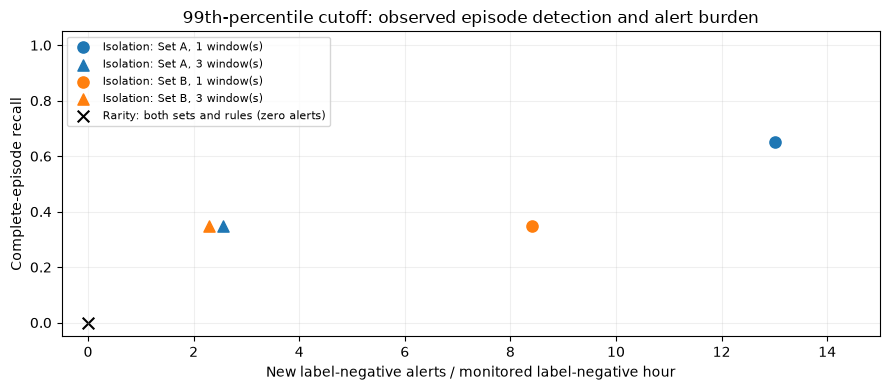

In [8]:
policy_rows = []
keys = ['calibration_seconds', 'population', 'method', 'feature_set', 'quantile', 'consecutive']
for identity, group in metrics.groupby(keys):
    total = group[['requested', 'decision_available', 'complete_episodes', 'detected_episodes',
                   'censored_positive_pieces', 'label_negative_alerts', 'unknown_label_alert_starts',
                   'monitored_negative_seconds', 'alert_negative_seconds', 'positive_bins_total',
                   'positive_bins_detected']].sum()
    matching = np.ones(len(events), dtype=bool)
    for key, value in zip(keys, identity):
        matching &= events[key].eq(value).to_numpy()
    delays = events.loc[matching & events.detected & events.complete & events.in_assessment, 'delay_s']
    negative_seconds = total.monitored_negative_seconds
    policy_rows.append({**dict(zip(keys, identity)), **total.to_dict(),
                        'availability': total.decision_available / total.requested,
                        'episode_recall': total.detected_episodes / total.complete_episodes,
                        'median_detected_delay_s': delays.median(),
                        'negative_alerts_per_hour': total.label_negative_alerts / (negative_seconds / 3600),
                        'negative_time_in_alert': total.alert_negative_seconds / negative_seconds,
                        'all_positive_bin_recall': total.positive_bins_detected / total.positive_bins_total})
policy_summary = pd.DataFrame(policy_rows)
main_policies = policy_summary.loc[policy_summary.calibration_seconds.eq(60)
                                  & policy_summary.population.eq('common')
                                  & policy_summary['quantile'].eq(.99)]
columns = ['method', 'feature_set', 'consecutive', 'availability', 'detected_episodes', 'complete_episodes',
           'episode_recall', 'median_detected_delay_s', 'negative_alerts_per_hour',
           'negative_time_in_alert', 'all_positive_bin_recall']
display(main_policies[columns].round(3))
display(availability.loc[availability.calibration_seconds.eq(60)].groupby('feature_set').agg(
    requested=('requested', 'sum'), available=('available', 'sum')))
print('Censored positive pieces per specification:', int(main_policies.censored_positive_pieces.iloc[0]))
display(primary.loc[primary.method.eq('isolation') & primary.consecutive.eq(3)].groupby(
    ['family', 'feature_set'])[['complete_episodes', 'detected_episodes', 'label_negative_alerts']].sum())
print('Monitored label-negative exposure (hours):',
      round(main_policies.monitored_negative_seconds.iloc[0] / 3600, 3))
fig, ax = plt.subplots(figsize=(9, 4))
for row in main_policies.loc[main_policies.method.eq('isolation')].itertuples():
    ax.scatter(row.negative_alerts_per_hour, row.episode_recall,
               color='tab:blue' if row.feature_set == 'A_level' else 'tab:orange',
               marker='o' if row.consecutive == 1 else '^', s=65,
               label=f'Isolation: Set {row.feature_set[0]}, {row.consecutive} window(s)')
ax.scatter(0, 0, marker='x', s=70, color='black', label='Rarity: both sets and rules (zero alerts)')
ax.set(title='99th-percentile cutoff: observed episode detection and alert burden',
       xlabel='New label-negative alerts / monitored label-negative hour',
       ylabel='Complete-episode recall', ylim=(-.05, 1.05), xlim=(-.5, 15))
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(OUT / 'alert_tradeoffs.png', dpi=140, bbox_inches='tight'); plt.show()
policy_summary.to_csv(OUT / 'policy_summary.csv', index=False)

**Observed:** the shared vector availability is **4,864/5,150 = 94.45%**. There are **20 complete episodes** and **12 censored positive pieces** across the remaining six recordings; the latter are not part of the complete-episode recall denominator. Positive-bin coverage and recall still describe their observed portions.

For level-only Isolation Forest at the 99th-percentile cutoff, requiring three windows reduces label-negative starts from **51 to 10**, but also reduces detected complete episodes from **13 to 7**. The decrease in detected-only median delay (47 to 36 seconds) does **not** show that waiting makes alerts faster: the detected episode population changed. Use per-episode timings for a paired delay comparison.

Both feature sets with three-window persistence miss all **12 complete valve episodes**. This matters more for readiness than their favourable overall ranking. No acceptable alert budget has been established, and 3.923 monitored label-negative hours is too little to validate a production burden.

## 7. Inspect what a score and an alert mean on real recordings

The examples were chosen before detector evaluation: `valve1/1` and `other/10`, also used in Notebook 03. Shading is retrospective annotation, not an input. Feature traces retain physical units. The rarity components can identify which measured departure drives that score; they do not identify a root cause. Isolation Forest's scalar score is shown without an unsupported sensor-causality explanation.

The alert strip uses the primary 99th-percentile cutoff and three consecutive windows. Alerts appear at their actual issue time. A score above its cutoff for one or two windows is not yet an alert under this policy.

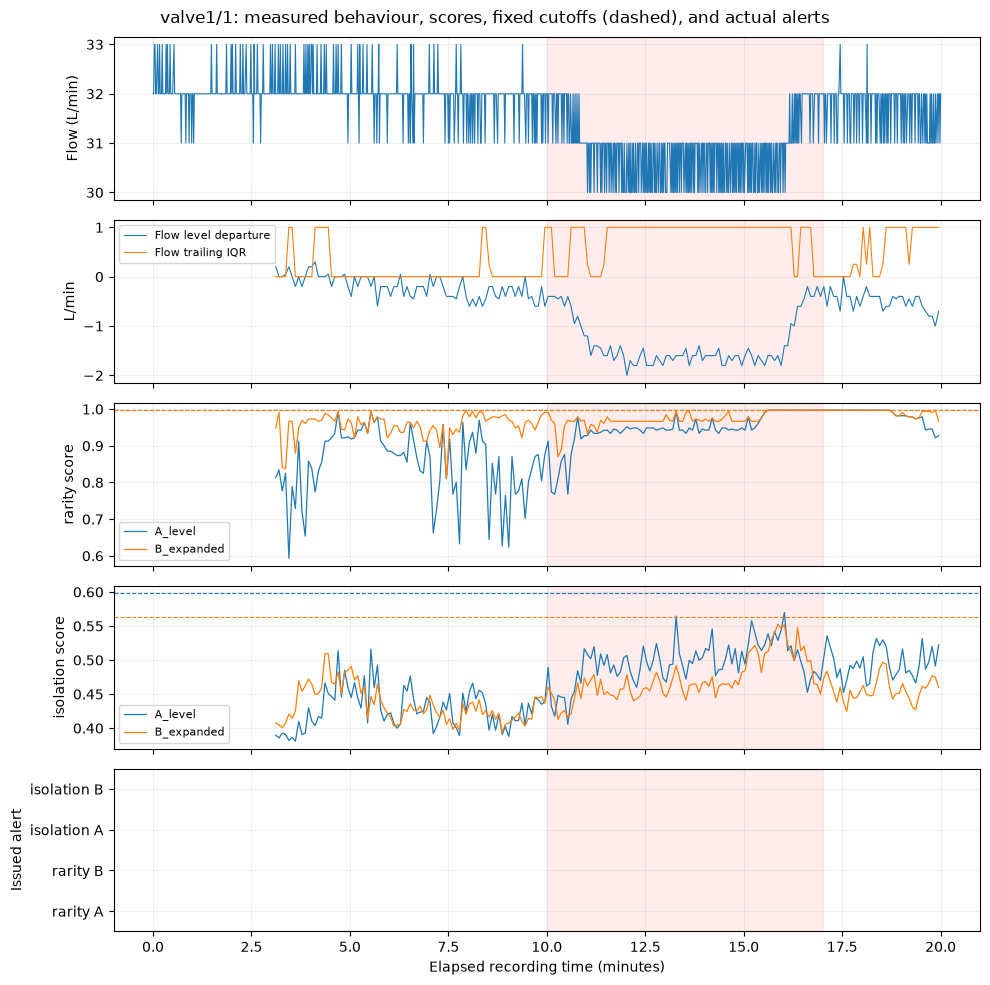

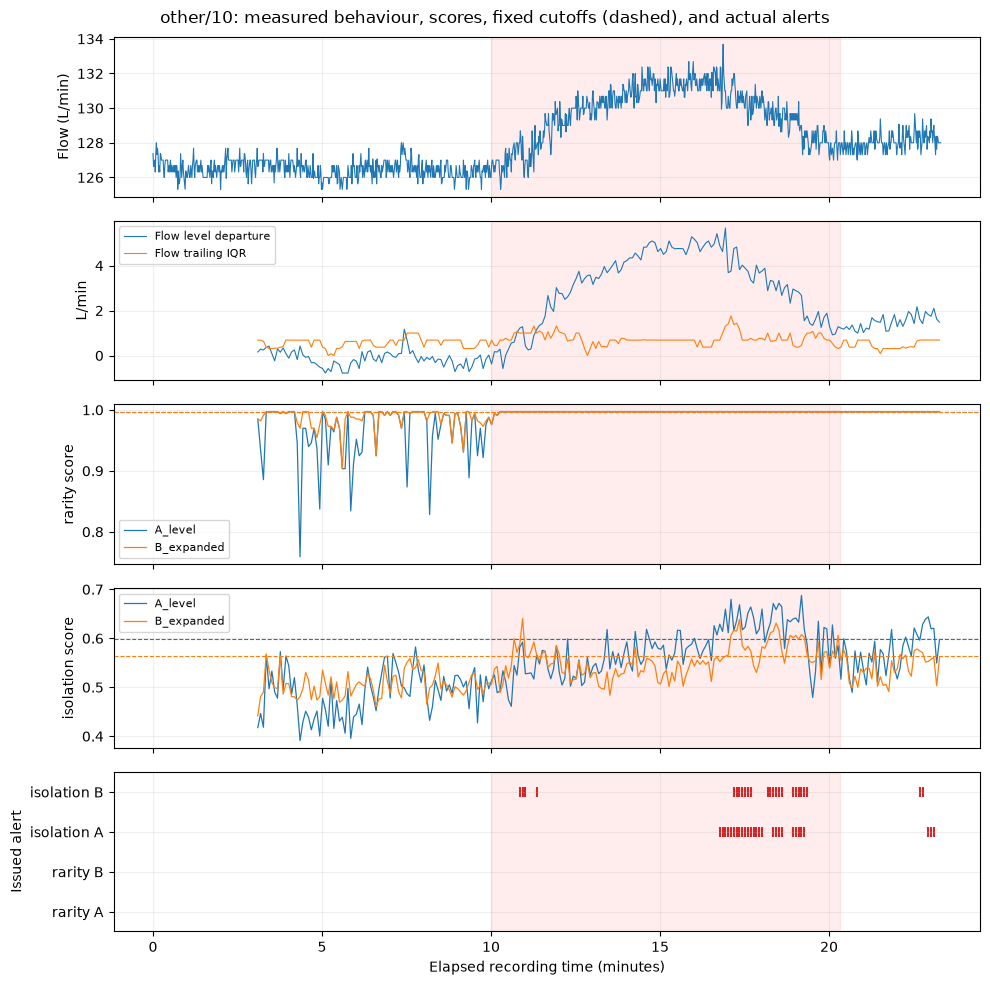

In [9]:
for name in ['valve1/1', 'other/10']:
    origin = recordings[name].timestamp.iloc[0]
    native = recordings[name].set_index('timestamp')
    value = features[60, name]
    minutes = (value.index - origin).total_seconds() / 60
    fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
    axes[0].plot((native.index - origin).total_seconds() / 60, native['Volume Flow RateRMS'], linewidth=.8)
    axes[0].set_ylabel('Flow (L/min)')
    axes[1].plot(minutes, value['Volume Flow RateRMS__level'], label='Flow level departure', linewidth=.8)
    axes[1].plot(minutes, value['Volume Flow RateRMS__iqr'], label='Flow trailing IQR', linewidth=.8)
    axes[1].set_ylabel('L/min'); axes[1].legend(fontsize=8, loc='best')
    for ax, method in zip(axes[2:4], ['rarity', 'isolation']):
        for set_name, colour in [('A_level', 'tab:blue'), ('B_expanded', 'tab:orange')]:
            selected = decisions.loc[decisions.recording_id.eq(name) & decisions.calibration_seconds.eq(60)
                & decisions.population.eq('common') & decisions['quantile'].eq(.99)
                & decisions.consecutive.eq(3) & decisions.method.eq(method) & decisions.feature_set.eq(set_name)]
            x = (selected.timestamp - origin).dt.total_seconds() / 60
            ax.plot(x, selected.score, color=colour, label=set_name, linewidth=.9)
            ax.axhline(selected.threshold.iloc[0], color=colour, linestyle='--', linewidth=.8)
        ax.set_ylabel(method + ' score'); ax.legend(fontsize=8, loc='best')
    lanes = [('rarity', 'A_level'), ('rarity', 'B_expanded'), ('isolation', 'A_level'), ('isolation', 'B_expanded')]
    for lane, (method, set_name) in enumerate(lanes):
        selected = decisions.loc[decisions.recording_id.eq(name) & decisions.calibration_seconds.eq(60)
            & decisions.population.eq('common') & decisions['quantile'].eq(.99)
            & decisions.consecutive.eq(3) & decisions.method.eq(method) & decisions.feature_set.eq(set_name)]
        active = selected.loc[selected.alarm.eq(1)]
        axes[4].scatter((active.timestamp - origin).dt.total_seconds() / 60,
                        np.full(len(active), lane), marker='|', s=50, color='tab:red')
    axes[4].set(yticks=range(4), yticklabels=[f'{method} {group[0]}' for method, group in lanes],
                xlabel='Elapsed recording time (minutes)', ylabel='Issued alert', ylim=(-.5, 3.5))
    for event in observed_episodes(native_labels[name]).itertuples():
        end = event.end if pd.notna(event.end) else event.last
        for ax in axes:
            ax.axvspan((event.start - origin).total_seconds() / 60,
                       (end - origin).total_seconds() / 60, color='red', alpha=.07)
    fig.suptitle(f'{name}: measured behaviour, scores, fixed cutoffs (dashed), and actual alerts')
    fig.tight_layout(); fig.savefig(OUT / (name.replace('/', '_') + '_decisions.png'), dpi=140); plt.show()

**Reading these examples.** In `valve1/1`, flow falls during the shaded interval, and Isolation Forest's score generally rises. Nevertheless, neither primary cutoff/persistence combination issues an alert. A visible physical departure and a useful within-recording ranking do not ensure threshold transfer.

In `other/10`, the expanded model first alerts **51 seconds** after the first positive annotation, compared with **406 seconds** for the level-only model. That local benefit coexists with worse aggregate ranking for the expanded set. Rarity reaches its ceiling but never exceeds its ceiling-valued cutoff. The flow panels explain one observed change; the scores use all input features, so the panels do not establish the cause of an alert.

## 8. Gaps and unsupported calibration are monitoring outcomes

`other/2` contains a 247-second collection gap. The feature history resets, and a persistence alert has to rebuild its own run after a score becomes available. Its positive-label run is gap-censored; we do not infer an exact intervention onset through the gap. With 180-second local calibration, this recording fails the occupancy rule and its level-based detector vectors remain unavailable.

`other/13` fails both local calibration durations. Its lack of a complete detector vector remains a monitoring failure, not a correct negative prediction. Point metrics on available rows alone would conceal this limitation.

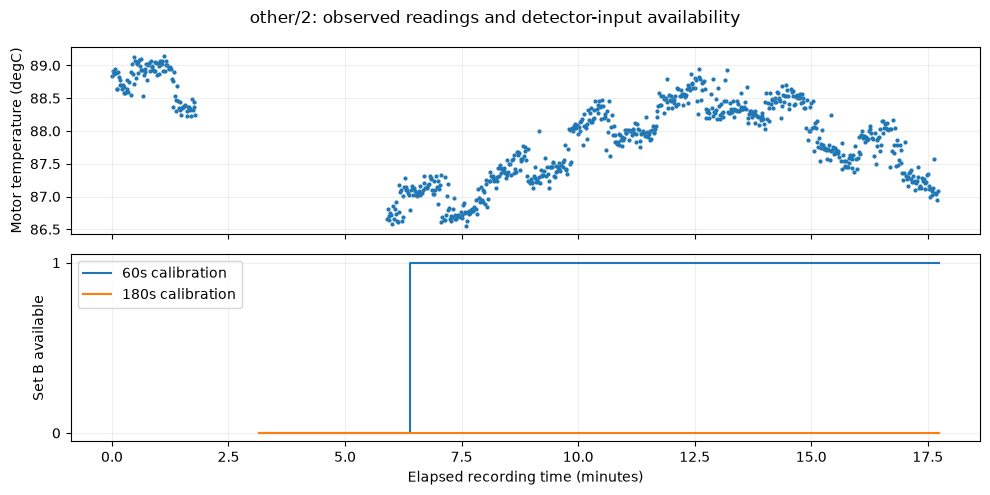

,recording_id,calibration_seconds,feature_set,requested,available,candidate_normal_rows
12,other/13,60,A_level,190,0,0
13,other/13,60,B_expanded,190,0,0
14,other/13,180,A_level,190,0,0
15,other/13,180,B_expanded,190,0,0
20,other/2,60,A_level,176,142,0
21,other/2,60,B_expanded,176,137,0
22,other/2,180,A_level,176,0,0
23,other/2,180,B_expanded,176,0,0


In [10]:
name = 'other/2'
origin = recordings[name].timestamp.iloc[0]
raw = recordings[name]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].scatter((raw.timestamp - origin).dt.total_seconds() / 60, raw.Temperature, s=4)
axes[0].set_ylabel('Motor temperature (degC)')
for duration, colour in [(60, 'tab:blue'), (180, 'tab:orange')]:
    values = features[duration, name]
    support = values.notna().all(axis=1)
    axes[1].step((values.index - origin).total_seconds() / 60, support.astype(int),
                 where='post', label=f'{duration}s calibration', color=colour)
axes[1].set(xlabel='Elapsed recording time (minutes)', ylabel='Set B available', yticks=[0, 1])
axes[1].legend(); fig.suptitle('other/2: observed readings and detector-input availability')
fig.tight_layout(); fig.savefig(OUT / 'gap_and_calibration.png', dpi=140); plt.show()
display(availability.loc[availability.recording_id.isin(['other/2', 'other/13']),
    ['recording_id', 'calibration_seconds', 'feature_set', 'requested', 'available', 'candidate_normal_rows']])

## 9. Predeclared sensitivity checks; no selection of the best-looking setting

Cutoff percentile, alert persistence and local calibration duration affect different parts of the experiment. We show all combinations rather than choosing them using event recall. The 60/180-second comparison below also evaluates ranking on their **intersection of eligible timestamps**; otherwise a calibration failure could appear to improve results merely by removing a difficult recording.

Isolation Forest is repeated with seeds 17 and 91 as a stability check. Every seed has its own cutoff from the same cutoff-calibration recordings. We report the range, not the best seed. No detector is refitted using assessment labels.

In [11]:
display(policy_summary.loc[policy_summary.population.eq('common'),
    ['calibration_seconds', 'method', 'feature_set', 'quantile', 'consecutive', 'availability',
     'episode_recall', 'negative_alerts_per_hour', 'negative_time_in_alert']].round(3))
calibration_comparison = []
for name in development_ids:
    shared = features[60, name].notna().all(axis=1) & features[180, name].notna().all(axis=1)
    for set_name in feature_sets:
        for method in ['rarity', 'isolation']:
            for duration in [60, 180]:
                scores = scoring[duration, name, set_name, method]
                summary = point_metrics(window_labels[name].label, scores,
                                        pd.Series(0., index=scores.index), shared)
                calibration_comparison.append({'recording_id': name, 'method': method,
                    'feature_set': set_name, 'calibration_seconds': duration,
                    'average_precision': summary.average_precision, 'common': summary.common})
calibration_comparison = pd.DataFrame(calibration_comparison)
display(calibration_comparison.groupby(['method', 'feature_set', 'calibration_seconds']).agg(
    available_recordings=('average_precision', 'count'), mean_AP=('average_precision', 'mean'),
    common_bins=('common', 'sum')).round(3))
calibration_comparison.to_csv(OUT / 'calibration_paired_ranking.csv', index=False)

,calibration_seconds,method,feature_set,quantile,consecutive,availability,episode_recall,negative_alerts_per_hour,negative_time_in_alert
0,60,isolation,A_level,0.95,1,0.944,0.80,19.120,0.092
1,60,isolation,A_level,0.95,3,0.944,0.40,4.844,0.054
2,60,isolation,A_level,0.99,1,0.944,0.65,13.002,0.043
3,60,isolation,A_level,0.99,3,0.944,0.35,2.549,0.019
4,60,isolation,B_expanded,0.95,1,0.944,0.75,18.101,0.073
5,60,isolation,B_expanded,0.95,3,0.944,0.50,4.079,0.039
6,60,isolation,B_expanded,0.99,1,0.944,0.35,8.413,0.033
7,60,isolation,B_expanded,0.99,3,0.944,0.35,2.294,0.016
8,60,rarity,A_level,0.95,1,0.944,0.00,0.000,0.000
9,60,rarity,A_level,0.95,3,0.944,0.00,0.000,0.000


available_recordings  mean_AP  \
method    feature_set calibration_seconds                                  
isolation A_level     60                                     24    0.807   
                      180                                    24    0.851   
          B_expanded  60                                     24    0.769   
                      180                                    24    0.776   
rarity    A_level     60                                     24    0.714   
                      180                                    24    0.734   
          B_expanded  60                                     24    0.695   
                      180                                    24    0.708   

                                           common_bins  
method    feature_set calibration_seconds               
isolation A_level     60                        4689.0  
                      180                       4689.0  
          B_expanded  60                        4689.0  
                      180                       4689.0  
rarity    A_level     60                        4689.0  
                      180                       4689.0  
          B_expanded  60                        4689.0  
                      180                       4689.0

In [12]:
seed_rows = []
for seed in experiment['sensitivity_seeds']:
    for fold in range(3):
        cutoff_ids = folds.index[folds.fold.eq((fold + 2) % 3)].tolist()
        assess_ids = folds.index[folds.fold.eq(fold)].tolist()
        for set_name, columns in feature_sets.items():
            fit_values = training_values[60, fold, set_name]
            cutoff_values = pd.concat([features[60, name].loc[reference_masks[60, name], columns]
                                       for name in cutoff_ids])
            forest = IsolationForest(n_estimators=experiment['isolation_trees'],
                                     max_samples=experiment['isolation_max_samples'],
                                     random_state=seed, n_jobs=1).fit(fit_values)
            threshold = calibrate_threshold(pd.Series(-forest.score_samples(cutoff_values)), .99).threshold
            for name in assess_ids:
                values = features[60, name][columns]
                common = features[60, name].notna().all(axis=1)
                scores = pd.Series(np.nan, index=values.index)
                if common.any():
                    scores.loc[common] = -forest.score_samples(values.loc[common])
                alarm = causal_alerts(scores, threshold, 3, frequency=step)
                point = point_metrics(window_labels[name].label, scores, alarm.alarm)
                episode, _ = episode_metrics(native_labels[name], alarm, frequency=step, max_gap=settings['gap_threshold'])
                seed_rows.append({'seed': seed, 'feature_set': set_name, 'recording_id': name,
                                  'threshold': threshold, **point.to_dict(), **episode.to_dict()})
seed_metrics = pd.DataFrame(seed_rows)
primary_seed = primary.loc[primary.method.eq('isolation') & primary.consecutive.eq(3)].assign(
    seed=experiment['primary_seed'])
seed_metrics = pd.concat([seed_metrics, primary_seed], ignore_index=True)
seed_summary = seed_metrics.groupby(['seed', 'feature_set']).agg(
    mean_AP=('average_precision', 'mean'), detected=('detected_episodes', 'sum'),
    complete=('complete_episodes', 'sum'), negative_alerts=('label_negative_alerts', 'sum'),
    negative_seconds=('monitored_negative_seconds', 'sum'))
seed_summary['episode_recall'] = seed_summary.detected / seed_summary.complete
seed_summary['negative_alerts_per_hour'] = seed_summary.negative_alerts / (seed_summary.negative_seconds / 3600)
display(seed_summary[['mean_AP', 'episode_recall', 'negative_alerts_per_hour']].round(3))
seed_metrics.to_csv(OUT / 'isolation_seed_sensitivity.csv', index=False)

mean_AP  episode_recall  negative_alerts_per_hour
seed feature_set                                                   
17   A_level        0.789            0.35                     1.530
     B_expanded     0.752            0.35                     0.765
42   A_level        0.811            0.35                     2.549
     B_expanded     0.771            0.35                     2.294
91   A_level        0.782            0.35                     2.294
     B_expanded     0.730            0.30                     2.294

**Observed sensitivity.** On the same **24 available recordings and 4,689 pure-label common bins**, increasing calibration from 60 to 180 seconds raises level-only Isolation Forest mean AP from **0.807 to 0.851**; expanded-model AP changes from **0.769 to 0.776**. This is conditional on shared support: the 180-second protocol loses `other/2`, and neither protocol supports `other/13`. A longer initial information budget is not a free improvement.

Across the three declared seeds, level-only mean AP ranges **0.782–0.811** and expanded mean AP **0.730–0.771**. The primary three-window policy detects 7/20 complete episodes for every level-only seed and 6–7/20 for expanded features. Label-negative alert counts also vary. We retain seed 42 as declared; the smaller count from another seed is not a reason to select it.

## 10. Findings and next decision

**The 19-feature representation does not improve this initial detector comparison overall.** On the 25 recordings with supported primary vectors, mean per-recording AP is **0.811 for level-only Isolation Forest and 0.771 for expanded Isolation Forest**. Empirical rarity gives **0.701 and 0.683**, respectively. The constant-score reference averages **0.412** on the same populations. Some individual recordings improve with temporal features, but the results do not justify calling the expanded set superior.

**Ranking and usable alerts are different.** At the 99th-percentile cutoff and three-window rule, both Isolation Forest representations detect **7/20 complete episodes**. All seven are in `other`; neither detects the **12 fully observed valve episodes**. Set A creates **10 label-negative alert starts over 3.923 monitored label-negative hours** (2.55/hour), and Set B creates **9** (2.29/hour). These are short development exposures, not operational rate estimates. Detected-only median delays are 36 and 22 seconds; neither includes the 13 missed complete episodes.

**The transparent rarity comparator fails as an alert generator under the declared cutoffs.** Its calibration percentiles reach its finite score ceiling, so strict exceedance never occurs. It produces no alerts at either declared percentile under the primary calibration. Its nonzero AP cannot rescue this policy. Changing `>` to `>=` after seeing the results would be a new experiment, not a correction to the current one.

| Component | Recommendation from this experiment | Remaining limitation |
|---|---|---|
| Eight level departures | Keep as the primary feature comparator | Initial local calibration is short and may not represent later normal conditions |
| All 19 features | Retain as a documented alternative; no overall benefit established | Temporal descriptions can add ordinary cycling or drift as well as useful changes |
| Empirical-rarity components | Useful for transparent reference diagnostics; do not deploy the saturated alert policy | No severity information beyond fitted extremes |
| Isolation Forest | Keep as a development baseline; not ready for deployment | Thresholds miss every fully observed valve episode under the primary persistence rule |
| Three-window persistence | Keep as an explicit burden/detection trade-off | Reduces short alerts and can miss short or intermittent departures |
| Calibration/support rules | Retain unavailable outcomes and audit them | `other/13` is unmonitored; longer calibration additionally loses `other/2` |

**Next scientific question:** can a simple reference score and cutoff transfer across the different ordinary variability patterns without hiding the smaller valve departures? Investigate the candidate-normal score distributions and physical regime differences first. The intervention family must not become an operational predictor merely because it improves evaluation. A revised score, a justified normal-regime definition or a different support policy would require a separately declared development experiment.

The current notebook is an executed comparison and an honest failure analysis, **not a selected production detector**. Keep the reserved experiments closed while those choices remain unsettled. Once a policy is frozen, final evaluation must use those untouched recordings with the same local-calibration allowance and availability rules.

Labels assist only the training-reference selection and retrospective evaluation. A label-free protocol is a different experiment. One testbed, short dependent recordings, 20 complete observed episodes and incomplete incident boundaries cannot establish field reliability, failure prediction or cross-industry performance.

In [13]:
# Provenance describes exactly which data, definitions and software produced the outputs.
source_files = [record for record in settings['files'] if record['partition'] != 'reserved_test']
provenance = {
    'source_commit': settings['source_commit'], 'opened_files': source_files,
    'model_population': development_ids, 'reserved_files_opened': [],
    'normal_file_used_for_models': False, 'feature_sets': feature_sets,
    'experiment': experiment, 'local_calibration': baseline_settings,
    'feature_settings': feature_settings,
    'versions': {package: version(package) for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']},
    'source_sha256': {path: hashlib.sha256((ROOT / path).read_bytes()).hexdigest() for path in [
        'src/ts_anomaly/features.py', 'src/ts_anomaly/baselines.py', 'src/ts_anomaly/detection.py',
        'src/ts_anomaly/evaluation.py', 'configs/skab.json']},
    'limits': ['Development comparisons only; no final-test claims.',
               'One physical testbed; recordings are not independent industrial assets.',
               'Candidate-normal training uses annotations; local calibration does not.',
               'No point adjustment; gap-censored episodes are not complete incidents.']}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))
assert set(provenance['model_population']).isdisjoint(reserved_ids)
print('Complete per-recording scores, decisions, components, support and provenance:', OUT)
print('Reserved recording values were not requested by the data loader.')

Complete per-recording scores, decisions, components, support and provenance: /Users/lilidopidze/Documents/ChatGPT/Anomaly Detection/implementation/scientific-foundation/outputs/skab_detection
Reserved recording values were not requested by the data loader.


### Methodological references

- [Official SKAB source](https://github.com/waico/SKAB/tree/b2c0d46c2971dcbfe71e26087b6d231998bb91c2): laboratory data and annotations; the project split and alert policies here are our choices.
- [scikit-learn: grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data): keeping groups separate addresses row-level leakage. It does not prove independence between runs on the same machine.
- [scikit-learn: novelty and outlier detection](https://scikit-learn.org/stable/modules/outlier_detection.html): reference-population assumptions.
- [scikit-learn: Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html): algorithm, continuous scores and the distinction from its binary cutoff.
- [scikit-learn: average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html): ranking metric definition.
- [Kim et al., *Towards a Rigorous Evaluation of Time-series Anomaly Detection*, AAAI 2022](https://arxiv.org/abs/2109.05257): point-adjustment can inflate apparent detection quality. We preserve actual point decisions and alert times.

The empirical-rarity formula, support rules, folds, quantiles and consecutive-window policies are transparent experimental specifications, not claimed universal best practices or probabilistic guarantees.